<a href="https://colab.research.google.com/github/laurenesilver/laurenesilver/blob/main/COMP4009_Term_Project_Gradient_Descent_in_Action.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gradient Descent in Action
**COMP 4009: Essential Math for Data Science and AI — Term Project (Optional Code Section)**

This notebook implements gradient descent for linear regression from scratch using NumPy, following the derivations in the written report. It checks the implementation against hand calculations, the normal equation, and scikit-learn, shows the effect of the learning rate, and reproduces every number quoted in the report, including the feature-scaling experiment in Section 8.4.

## 1. Data and the design matrix
The running example uses four customers: billing clarity ratings $x = [1, 2, 3, 4]$ and overall satisfaction $y = [2, 3, 5, 6]$. The design matrix $X$ puts a column of ones next to the $x$ values, so that $X\theta$ produces every prediction $\theta_0 + \theta_1 x_i$ at once (Report, Section 4.1).

In [1]:
import numpy as np

# Running example data
x = np.array([1, 2, 3, 4])
y = np.array([2, 3, 5, 6])
n = len(y)

# Design matrix: a column of ones next to the x values
X = np.column_stack([np.ones(n), x])
print(X)

[[1. 1.]
 [1. 2.]
 [1. 3.]
 [1. 4.]]


## 2. Cost and gradient functions
These implement the matrix-form formulas from the report (Sections 2 and 4):
- Cost: $J(\theta) = \frac{1}{2n}(X\theta - y)^T(X\theta - y)$
- Gradient: $\nabla J(\theta) = \frac{1}{n}X^T(X\theta - y)$

The printed values should match the hand calculations: $J(0,0) = 9.25$, $J(0.5, 1.4) = 0.025$, and $\nabla J(0,0) = (-4, -11.75)$.

In [2]:
def cost(theta, X, y):
    """Mean squared error cost: J = (1/2n) * sum of squared residuals."""
    n = len(y)
    residuals = X @ theta - y
    return (residuals @ residuals) / (2 * n)

def gradient(theta, X, y):
    """Gradient of the cost: (1/n) * X^T (X theta - y)."""
    n = len(y)
    return X.T @ (X @ theta - y) / n

# Check against the numbers from the write-up
theta = np.array([0.0, 0.0])
print(cost(theta, X, y))                   # expect 9.25
print(cost(np.array([0.5, 1.4]), X, y))    # expect 0.025
print(gradient(theta, X, y))               # expect [-4, -11.75]

9.25
0.025000000000000033
[ -4.   -11.75]


## 3. The gradient descent algorithm
Starting from $\theta = 0$, the algorithm repeatedly applies the update rule (Report, Section 5.3)

$$\theta \leftarrow \theta - \alpha \cdot \frac{1}{n}X^T(X\theta - y)$$

It stops when $\|\nabla J\| < 10^{-6}$ (converged) or after a maximum number of updates (a safety net in case it never converges).

The function records the cost before the first update and after every update, so `cost_history[k]` is the cost after `k` updates. It also returns the number of updates made and a `converged` flag, so a run that hits the cap is never mistaken for one that converged.

In [3]:
def gradient_descent(X, y, alpha, tol=1e-6, max_iters=10000):
    """Run gradient descent on the linear regression cost.

    Stops when the gradient's length falls below tol (converged)
    or after max_iters updates (safety net).

    Returns:
        theta        -- the final parameters
        cost_history -- cost_history[k] is the cost after k updates
        n_updates    -- the number of updates actually made
        converged    -- True if the gradient fell below tol
    """
    theta = np.zeros(X.shape[1])        # Step 1: start at theta = 0
    cost_history = [cost(theta, X, y)]  # cost before any update
    converged = False

    for n_updates in range(max_iters + 1):
        g = gradient(theta, X, y)        # Step 2: compute the gradient
        if np.linalg.norm(g) < tol:      # Step 3: converged? then stop
            converged = True
            break
        if n_updates == max_iters:       # safety net: no more updates allowed
            break
        theta = theta - alpha * g        # Step 4: update rule
        cost_history.append(cost(theta, X, y))

    return theta, cost_history, n_updates, converged

## 4. Running gradient descent
With learning rate $\alpha = 0.1$, the algorithm converges in 539 updates to $\theta \approx (0.5, 1.4)$, the best-fit line $\hat{y} = 0.5 + 1.4x$. The first few costs (9.25, 0.276, 0.032, 0.025) match the iteration table in Section 5.3 of the report.

In [4]:
theta, costs, iters, converged = gradient_descent(X, y, alpha=0.1)

print("theta:", theta)
print("updates:", iters, "| converged:", converged)
print("first costs:", np.round(costs[:4], 4))
print("final cost:", costs[-1])

theta: [0.49999371 1.40000214]
updates: 539 | converged: True
first costs: [9.25   0.2761 0.0319 0.0252]
final cost: 0.02500000000330834


## 5. Comparison with scikit-learn and the normal equation
Three independent methods should give the same parameters (Report, Section 7.1): our gradient descent, scikit-learn's `LinearRegression`, and solving the normal equation $X^TX\theta = X^Ty$ directly. Gradient descent differs only around the sixth decimal place, because it stops once it is *close enough* to the minimum rather than landing on it exactly.

In [5]:
from sklearn.linear_model import LinearRegression

# Fit scikit-learn's linear regression to the same data
model = LinearRegression()
model.fit(x.reshape(-1, 1), y)

print("sklearn intercept:", model.intercept_)
print("sklearn slope:", model.coef_[0])
print("gradient descent:", theta)

# Bonus: solve the normal equation from Section 4.3 directly
print("normal equation:", np.linalg.solve(X.T @ X, X.T @ y))

# Do the answers agree (within 0.0001)?
sklearn_theta = np.array([model.intercept_, model.coef_[0]])
print("match:", np.allclose(theta, sklearn_theta, atol=1e-4))

sklearn intercept: 0.5
sklearn slope: 1.4
gradient descent: [0.49999371 1.40000214]
normal equation: [0.5 1.4]
match: True


## 6. The effect of the learning rate
Cost over the first 49 updates (50 recorded points, iterations 0 to 49) for three learning rates, on a log scale (Report, Section 6.2):
- $\alpha = 0.01$ (too small): the cost falls, but slowly.
- $\alpha = 0.1$ (good): the cost drops quickly and settles at the minimum.
- $\alpha = 0.25$ (too large): each step overshoots the minimum, so the cost grows instead of shrinking. This is divergence.

alpha = 0.01: cost after 49 updates = 0.0268
alpha = 0.1: cost after 49 updates = 0.0250
alpha = 0.25: cost after 49 updates = 34,515.6194


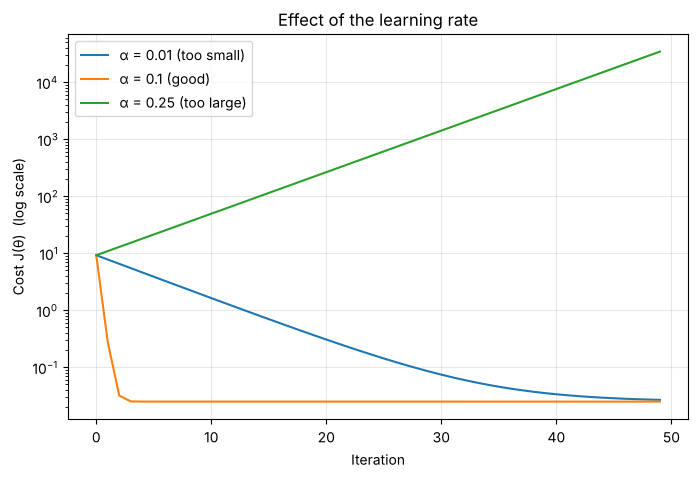

In [6]:
import matplotlib.pyplot as plt

learning_rates = [0.01, 0.1, 0.25]
labels = ["α = 0.01 (too small)", "α = 0.1 (good)", "α = 0.25 (too large)"]

plt.figure(figsize=(8, 5))

# Run 49 updates at each learning rate (50 recorded costs) and plot them
for alpha, label in zip(learning_rates, labels):
    _, history, _, _ = gradient_descent(X, y, alpha, max_iters=49)
    plt.plot(history, label=label)
    print(f"alpha = {alpha}: cost after 49 updates = {history[-1]:,.4f}")

plt.yscale("log")   # log scale so tiny and huge costs fit on one plot
plt.xlabel("Iteration")
plt.ylabel("Cost J(θ)  (log scale)")
plt.title("Effect of the learning rate")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Updates needed to converge
The iteration counts quoted in Section 6.2 of the report, using the stopping rule $\|\nabla J\| < 10^{-6}$. Note that the counts depend on that strict tolerance: by iteration 50, $\alpha = 0.01$ is already within about 7% of the minimum cost.

In [7]:
for alpha in [0.01, 0.1]:
    _, history, n_updates, converged = gradient_descent(X, y, alpha)
    print(f"alpha = {alpha}: {n_updates:,} updates, converged = {converged}")

ratio = gradient_descent(X, y, 0.01)[2] / gradient_descent(X, y, 0.1)[2]
print(f"alpha = 0.01 needs {ratio:.1f}x as many updates as alpha = 0.1")

alpha = 0.01: 5,424 updates, converged = True
alpha = 0.1: 539 updates, converged = True
alpha = 0.01 needs 10.1x as many updates as alpha = 0.1


## 7. Where the limit on the learning rate comes from
The eigenvalues of $\frac{1}{n}X^TX$ describe the curvature of the bowl (Report, Section 6.3). Gradient descent converges only when $\alpha < 2/\lambda_{\max}$, and the condition number $\lambda_{\max}/\lambda_{\min}$ explains why convergence takes hundreds of steps.

In [8]:
H = X.T @ X / n
eigenvalues = np.linalg.eigvalsh(H)   # eigvalsh: for symmetric matrices, sorted ascending
lam_min, lam_max = eigenvalues

print("X^T X / n =\n", H)
print(f"lambda_min = {lam_min:.4f}, lambda_max = {lam_max:.4f}")
print(f"learning rate limit 2 / lambda_max = {2 / lam_max:.4f}")
print(f"condition number = {lam_max / lam_min:.1f}")

X^T X / n =
 [[1.  2.5]
 [2.5 7.5]]
lambda_min = 0.1497, lambda_max = 8.3503
learning rate limit 2 / lambda_max = 0.2395
condition number = 55.8


## 8. The path on the error surface
Contour lines of $J(\theta_0, \theta_1)$ with the path gradient descent takes from $(0, 0)$ to the minimum at $(0.5, 1.4)$, using $\alpha = 0.1$ (the figure on slides 1 and 7 of the presentation). The first step covers most of the distance; the remaining updates creep along the bowl's flat direction.

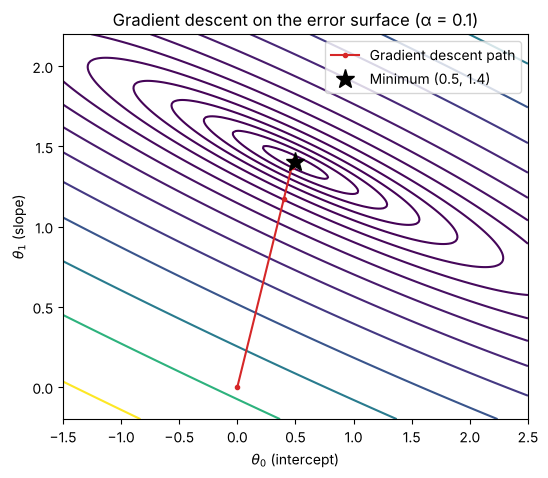

In [9]:
# Record the parameters after every update
path = [np.zeros(2)]
for _ in range(539):
    path.append(path[-1] - 0.1 * gradient(path[-1], X, y))
path = np.array(path)

# Evaluate J on a grid of (theta0, theta1) values
t0, t1 = np.meshgrid(np.linspace(-1.5, 2.5, 200), np.linspace(-0.2, 2.2, 200))
J_grid = np.array([[cost(np.array([a, b]), X, y) for a, b in zip(r0, r1)]
                   for r0, r1 in zip(t0, t1)])

plt.figure(figsize=(6, 5))
plt.contour(t0, t1, J_grid, levels=np.logspace(-1.5, 1.2, 15), cmap="viridis")
plt.plot(path[:, 0], path[:, 1], "o-", color="tab:red", markersize=3, label="Gradient descent path")
plt.plot(0.5, 1.4, "*", color="black", markersize=14, label="Minimum (0.5, 1.4)")
plt.xlabel(r"$\theta_0$ (intercept)")
plt.ylabel(r"$\theta_1$ (slope)")
plt.title("Gradient descent on the error surface (α = 0.1)")
plt.legend()
plt.show()

## 9. The fitted line
The four customers with the line found by gradient descent, $\hat{y} = 0.5 + 1.4x$ (Report, Figure 2).

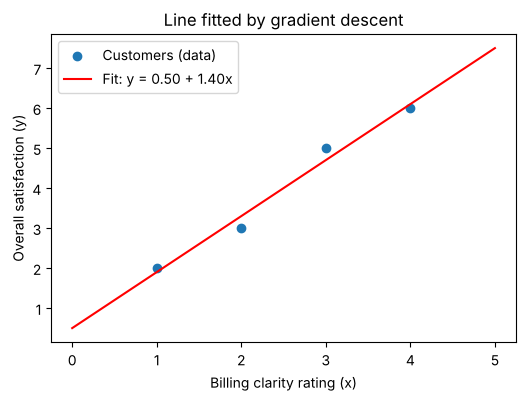

In [10]:
plt.figure(figsize=(6, 4))
plt.scatter(x, y, label="Customers (data)")

# Draw the line y = theta0 + theta1 * x across the range of the data
x_line = np.linspace(0, 5, 100)
plt.plot(x_line, theta[0] + theta[1] * x_line, color="red",
         label=f"Fit: y = {theta[0]:.2f} + {theta[1]:.2f}x")

plt.xlabel("Billing clarity rating (x)")
plt.ylabel("Overall satisfaction (y)")
plt.title("Line fitted by gradient descent")
plt.legend()
plt.show()

## 10. Automated tests
Six checks support the correctness of the code (Report, Section 7.2):
1. The cost matches the hand calculations.
2. The gradient matches Section 4 and equals zero at the minimum.
3. Gradient descent matches scikit-learn on the running example.
4. With a good learning rate, the cost never increases.
5. A too-large learning rate ($\alpha = 0.25$) diverges.
6. The matrix form works with three features, not just one, and still matches scikit-learn.

In [11]:
def run_tests():
    """Automatic checks on the gradient descent code."""

    # Test 1: cost matches the hand calculations (Report, Section 2)
    assert np.isclose(cost(np.array([0.0, 0.0]), X, y), 9.25), "cost at (0, 0) should be 9.25"
    assert np.isclose(cost(np.array([0.5, 1.4]), X, y), 0.025), "cost at best fit should be 0.025"

    # Test 2: gradient matches Section 4, and is zero at the minimum
    assert np.allclose(gradient(np.array([0.0, 0.0]), X, y), [-4, -11.75]), "gradient at (0, 0) is wrong"
    assert np.allclose(gradient(np.array([0.5, 1.4]), X, y), [0, 0]), "gradient should be 0 at the minimum"

    # Test 3: gradient descent converges and matches scikit-learn on the running example
    theta_gd, costs_gd, _, converged = gradient_descent(X, y, alpha=0.1)
    assert converged, "GD should converge with alpha = 0.1"
    model = LinearRegression().fit(x.reshape(-1, 1), y)
    assert np.allclose(theta_gd, [model.intercept_, model.coef_[0]], atol=1e-4), "GD does not match sklearn"

    # Test 4: with a good learning rate, the cost never goes up
    assert np.all(np.diff(costs_gd) <= 1e-12), "cost increased during descent"

    # Test 5: a too-large learning rate diverges
    _, costs_big, _, converged_big = gradient_descent(X, y, alpha=0.25, max_iters=20)
    assert costs_big[-1] > costs_big[0] and not converged_big, "alpha = 0.25 should diverge"

    # Test 6: the matrix form works with several features, not just one
    rng = np.random.default_rng(0)
    features = rng.normal(size=(100, 3))
    target = 2 + features @ np.array([1.5, -3.0, 0.5]) + rng.normal(scale=0.1, size=100)
    X_multi = np.column_stack([np.ones(100), features])
    theta_multi, _, _, converged_multi = gradient_descent(X_multi, target, alpha=0.1)
    assert converged_multi, "GD should converge on the three-feature data"
    model_multi = LinearRegression().fit(features, target)
    expected = np.concatenate([[model_multi.intercept_], model_multi.coef_])
    assert np.allclose(theta_multi, expected, atol=1e-4), "GD does not match sklearn with 3 features"

    print("All 6 tests passed!")

run_tests()

All 6 tests passed!


## 11. Why features must be on the same scale
This section reproduces the worked example in Section 8.4 of the report, using a **simulated** survey (not real company data).

**How the data is generated** (seed 42, so the results are reproducible):
- 300 customers.
- Three 1–7 ratings (billing clarity, provisioning speed, support quality). They share a common "overall mood" component, so they are positively correlated, as real survey ratings usually are.
- Monthly logins, a whole number from 0 to 2,000.
- Overall satisfaction = 1.0 + 0.6 × billing + 0.4 × provisioning + 0.3 × support + 0.0005 × logins + random noise.

Gradient descent is run twice, first on the raw features and then on standardized features, each time with a learning rate chosen safely below that problem's limit. The benchmark in both cases is scikit-learn fit on the raw features.

In [12]:
# --- Simulate the survey ---
rng = np.random.default_rng(42)
n_sim = 300

mood = rng.normal(size=n_sim)   # shared component, makes the ratings correlated
def rating():
    return np.clip(np.round(4 + 1.2 * mood + rng.normal(size=n_sim)), 1, 7)

billing, provisioning, support = rating(), rating(), rating()
logins = rng.integers(0, 2001, size=n_sim).astype(float)

satisfaction = (1.0 + 0.6 * billing + 0.4 * provisioning + 0.3 * support
                + 0.0005 * logins + rng.normal(scale=0.6, size=n_sim))

features = np.column_stack([billing, provisioning, support, logins])
names = ["billing", "provisioning", "support", "logins"]

print("Correlation between the three ratings:")
print(np.round(np.corrcoef(features[:, :3].T), 2))

# Benchmark: scikit-learn on the raw features
sk = LinearRegression().fit(features, satisfaction)
sk_theta = np.concatenate([[sk.intercept_], sk.coef_])
print("\nscikit-learn weights:", dict(zip(["intercept"] + names, np.round(sk_theta, 4))))

Correlation between the three ratings:
[[1.   0.43 0.46]
 [0.43 1.   0.55]
 [0.46 0.55 1.  ]]

scikit-learn weights: {'intercept': np.float64(0.9766), 'billing': np.float64(0.5892), 'provisioning': np.float64(0.3914), 'support': np.float64(0.318), 'logins': np.float64(0.0005)}


In [13]:
def describe(X_design, label):
    """Eigenvalues of X^T X / n, the learning rate limit, and the condition number."""
    eig = np.linalg.eigvalsh(X_design.T @ X_design / len(X_design))
    print(f"{label}: condition number = {eig.max() / eig.min():,.1f}, "
          f"largest safe learning rate = {2 / eig.max():.3g}")
    return eig

# --- Raw features ---
X_raw = np.column_stack([np.ones(n_sim), features])
eig_raw = describe(X_raw, "Raw")
alpha_raw = 1 / eig_raw.max()   # half the limit, safely convergent
theta_raw, _, n_raw, conv_raw = gradient_descent(X_raw, satisfaction, alpha_raw, max_iters=100_000)
print(f"  {n_raw:,} updates, converged = {conv_raw}")
print(f"  billing weight = {theta_raw[1]:.3f} (scikit-learn: {sk_theta[1]:.3f})")
print(f"  matches scikit-learn: {np.allclose(theta_raw, sk_theta, atol=1e-4)}")

# --- Standardized features ---
mu, sigma = features.mean(axis=0), features.std(axis=0)
Z = (features - mu) / sigma
X_std = np.column_stack([np.ones(n_sim), Z])
eig_std = describe(X_std, "\nStandardized")
alpha_std = 2 / (eig_std.max() + eig_std.min())   # the best fixed learning rate for this bowl
theta_std, _, n_std, conv_std = gradient_descent(X_std, satisfaction, alpha_std)
print(f"  {n_std:,} updates, converged = {conv_std}")

# Convert the standardized weights back to original units before comparing:
#   weight_j = theta_std_j / sigma_j
#   intercept = theta_std_0 - sum_j (theta_std_j * mu_j / sigma_j)
weights_back = theta_std[1:] / sigma
intercept_back = theta_std[0] - np.sum(theta_std[1:] * mu / sigma)
theta_back = np.concatenate([[intercept_back], weights_back])
print(f"  billing weight (original units) = {theta_back[1]:.3f} (scikit-learn: {sk_theta[1]:.3f})")
print(f"  matches scikit-learn: {np.allclose(theta_back, sk_theta, atol=1e-4)}")

Raw: condition number = 22,060,178.5, largest safe learning rate = 1.46e-06


  100,000 updates, converged = False
  billing weight = 0.351 (scikit-learn: 0.589)
  matches scikit-learn: False

Standardized: condition number = 4.4, largest safe learning rate = 1.01
  32 updates, converged = True
  billing weight (original units) = 0.589 (scikit-learn: 0.589)
  matches scikit-learn: True


**Reading the result.** With raw features, the login column makes the bowl extremely stretched. Any learning rate small enough to avoid diverging along the login direction barely moves the rating weights, so after 100,000 updates the weights are still far from the answer. After standardizing, gradient descent converges in a few dozen updates. Its weights, converted back to original units, match scikit-learn.

Even after standardizing, the condition number is above 1 because the three ratings are correlated. That is the "correlated drivers" issue from Section 8.2 showing up in the geometry of the bowl.

Standardized weights are "per standard deviation" of each feature. To rank drivers or report them as "per rating point," convert them back as shown above.

## Environment
Package versions used to produce the results above.

In [14]:
import sys, sklearn, matplotlib
print("Python", sys.version.split()[0])
print("NumPy", np.__version__, "| scikit-learn", sklearn.__version__, "| Matplotlib", matplotlib.__version__)

Python 3.12.3
NumPy 2.5.4 | scikit-learn 1.9.1 | Matplotlib 3.11.2
